## Initialize

In [1]:
import numpy
import random
import sys
import gzip
import matplotlib.pyplot as plt
import pylab

L = 100
num_sweeps = 10_000

state=numpy.zeros((L,L))

#initialize half to 0 and the other half to 1
state[0:100,0:50]=1

up = (0,-1)
down = (0,1)
left = (-1,0)
right = (1,0)

## Function to swap with neighbor

In [2]:

def swap_with_neighbor(x: int, y: int):
    """
        Function to swap given (x,y) co-ordinates with their neighbors.
        Args:
            x : x co-ordinate
            y : y co-ordinate
    """

    directions = [up,down,left,right]

    #Boundary conditions horizontal
    if x == 0:
        directions.remove(left)
    if x == L - 1:
        directions.remove(right)

    #Boundary conditions vertical
    if y == 0:
        directions.remove(up)
    if y == L - 1:
        directions.remove(down)

    random_direction = random.choice(directions)

    state[x][y], state[x+random_direction[0]][y+random_direction[1]] = state[x+random_direction[0]][y+random_direction[1]], state[x][y]


## Run Sweeps

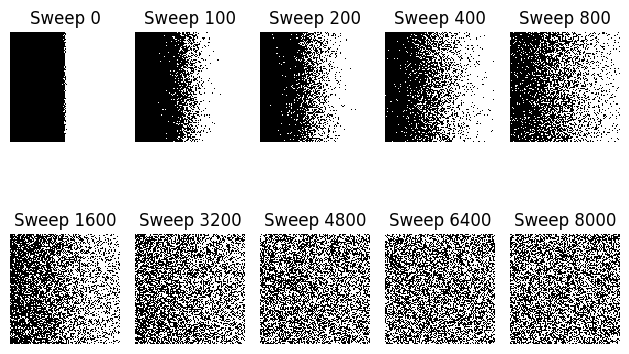

In [3]:

recordSweeps=[0,100,200,400,800,1600,3200,4800,6400,8000]
entropies = []

# 10 snapshots 2 x 5 grid?
fig_snapshots, axes = plt.subplots(2, 5)
axes = axes.flatten()

for i in range(num_sweeps):
    rand_x=numpy.random.randint(0,99,L**2)
    rand_y=numpy.random.randint(0,99,L**2)
    for j in range(L**2):
        x = rand_x[j]
        y = rand_y[j]

        swap_with_neighbor(x,y)
    if i in recordSweeps:
        entropy = sys.getsizeof(gzip.compress(state.tobytes()))
        entropies.append(entropy)

        idx = recordSweeps.index(i)
        axes[idx].imshow(state, cmap='binary', interpolation='nearest')
        axes[idx].set_title(f'Sweep {i}')
        # I dont like the labels on these snapshots, it looks cleaner this way
        axes[idx].axis('off')

plt.tight_layout()
plt.savefig('snapshots.png')
plt.show()

eq_state = numpy.zeros(L * L)
eq_state[: (L * L) // 2] = 1
numpy.random.shuffle(eq_state)
eq_state = eq_state.reshape((L, L))


eq_entropy = sys.getsizeof(gzip.compress(eq_state.tobytes()))

## Plot

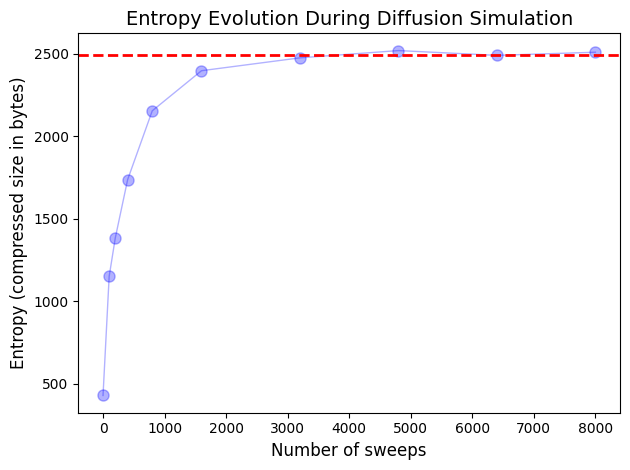

In [4]:

plt.figure()
plt.plot(recordSweeps, entropies, 'o-', markerfacecolor='blue', color='blue', alpha=.3, linewidth=1, label='System entropy', markersize=8)
plt.axhline(y=eq_entropy, color='r', linestyle='--', 
            label=f'Equilibrium entropy = {eq_entropy} bytes', linewidth=2)
plt.xlabel('Number of sweeps', fontsize=12)
plt.ylabel('Entropy (compressed size in bytes)', fontsize=12)
plt.title('Entropy Evolution During Diffusion Simulation', fontsize=14)
plt.tight_layout()
plt.savefig('entropy_vs_sweeps.png')
plt.show()

# To show equilibrium state
# plt.figure()
# plt.imshow(eq_state, cmap='binary', interpolation='nearest')
# plt.title('Equilibrium State (Random Configuration)', fontsize=14)
# plt.tight_layout()
# plt.show()

